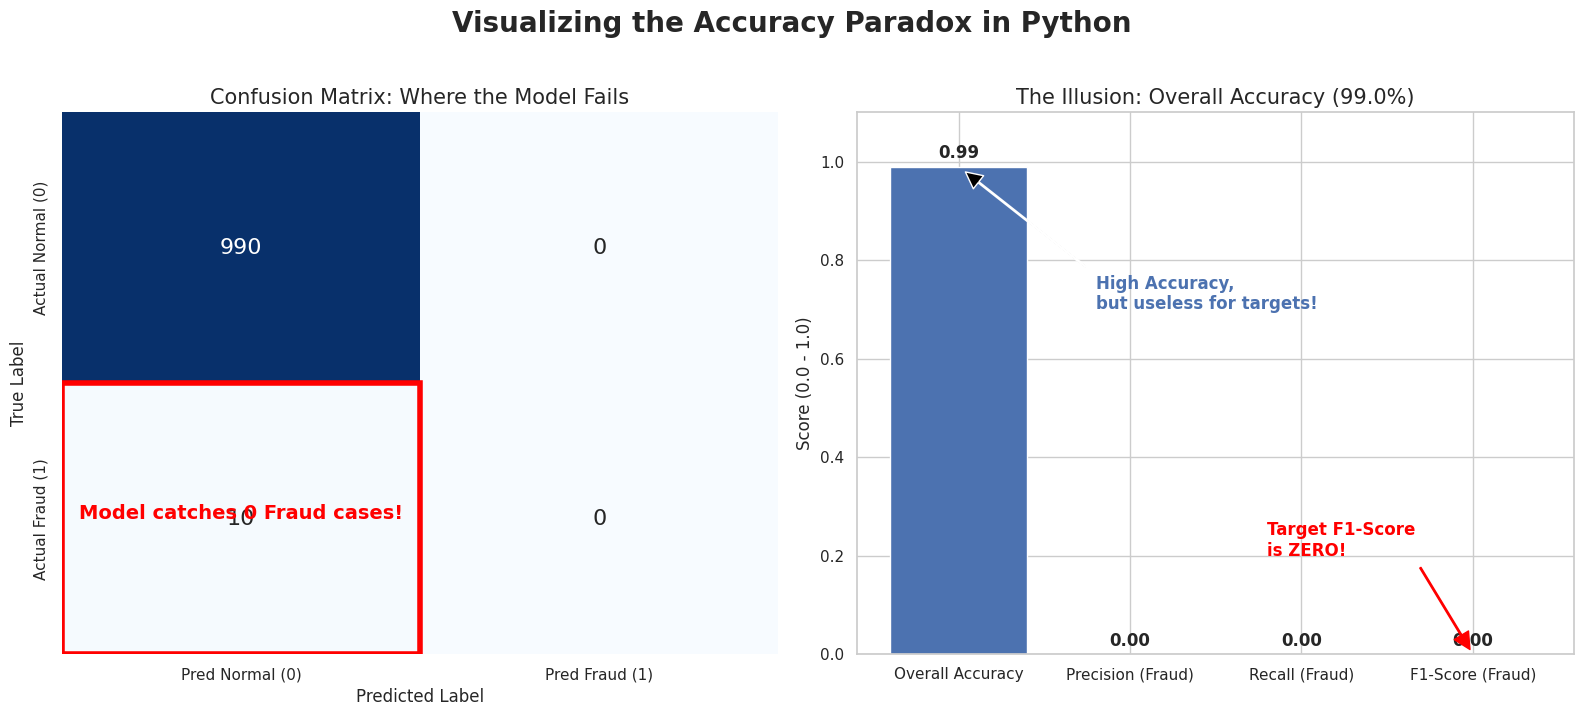

In [ ]:

#Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

def run_accuracy_paradox_demo():
    # Setup Highly Imbalanced Dataset (99% Normal, 1% Fraud)
    X_dummy = np.zeros((1000, 1)) 
    y_true = np.array([0] * 990 + [1] * 10) 
    
    # Train a Naive "Lazy" Model (Always predicts the majority class)
    lazy_model = DummyClassifier(strategy="most_frequent")
    lazy_model.fit(X_dummy, y_true)
    y_pred = lazy_model.predict(X_dummy)
    
    # Calculate All Metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision_1 = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    recall_1 = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1_1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    
    # START GRAPHING 
    sns.set_theme(style="whitegrid")
    
    # Create a figure with two subplots side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle('Visualizing the Accuracy Paradox in Python', fontsize=20, fontweight='bold', y=1.02)
    
    #  Plot 1: Confusion Matrix Heatmap 
    axes[0].set_title('Confusion Matrix: Where the Model Fails', fontsize=15)
    cm = confusion_matrix(y_true, y_pred)
    
    group_counts = ["{0:0.0f}".format(value) for value in cm.flatten()]
    labels = np.asarray(group_counts).reshape(2, 2)
    
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False,
                xticklabels=['Pred Normal (0)', 'Pred Fraud (1)'],
                yticklabels=['Actual Normal (0)', 'Actual Fraud (1)'],
                ax=axes[0], annot_kws={"size": 16})
    axes[0].set_ylabel('True Label', fontsize=12)
    axes[0].set_xlabel('Predicted Label', fontsize=12)
    
    # Highlight the missed fraud cases
    axes[0].add_patch(plt.Rectangle((0, 1), 1, 1, fill=False, edgecolor='red', lw=4))
    axes[0].text(0.5, 1.5, 'Model catches 0 Fraud cases!', color='red', fontsize=14, fontweight='bold', ha='center')

    #  Plot 2: Key Metrics Comparison 
    axes[1].set_title(f'The Illusion: Overall Accuracy ({accuracy*100:.1f}%)', fontsize=15)
    
    metrics_to_plot = ['Overall Accuracy', 'Precision (Fraud)', 'Recall (Fraud)', 'F1-Score (Fraud)']
    values_to_plot = [accuracy, precision_1, recall_1, f1_1]
    colors = ['#4c72b0', '#c44e52', '#ccb974', '#55a868']
    
    bars = axes[1].bar(metrics_to_plot, values_to_plot, color=colors)
    axes[1].set_ylabel('Score (0.0 - 1.0)', fontsize=12)
    axes[1].set_ylim(0, 1.1)
    
    for bar in bars:
        height = bar.get_height()
        axes[1].annotate(f'{height:.2f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    axes[1].annotate('High Accuracy,\nbut useless for targets!', xy=(0, accuracy), xytext=(0.8, 0.7),
                arrowprops=dict(facecolor='black', shrink=0.05, width=1), fontsize=12, fontweight='bold', color='#4c72b0')
    axes[1].annotate('Target F1-Score\nis ZERO!', xy=(3, 0), xytext=(1.8, 0.2),
                arrowprops=dict(facecolor='red', shrink=0.05, width=1, edgecolor='red'), fontsize=12, fontweight='bold', color='red')

    plt.tight_layout()
    plt.show() # Renders the visualization inline in your notebook

# Execute the function
run_accuracy_paradox_demo()